# PMU–DRL — Second manuscript revision: frozen-dataset integration

This notebook implements the **second revision stage**. It should be used only after the Data 1 completion work is finished and the corrected evaluation dataset has been frozen.

The freeze gate requires every expected algorithm–seed evaluation result in `data1`, `data2` and `data3` to be:

1. present; and
2. explicitly marked `verified` in the evaluation-trace audit.

Current author feedback establishes `data1/PPO/1024` as verified, leaves the other 24 Data 1 combinations pending, and states that Data 2 and Data 3 passed the current input-mapping checks. The notebook therefore **will not silently treat file presence as trace correctness**.

Once the gate passes, this notebook produces the final notebook-based refinements for the paper:

- final five-seed statistics and exact paired tests;
- cross-dataset/trace robustness and rank stability;
- source-to-controlled reduction using the corrected frozen data;
- conditional controller-overhead break-even analysis;
- energy–source-defined-constraint Pareto analysis;
- action-component observational sensitivity;
- state/history predictive sensitivity;
- record-density robustness;
- temporal-drift diagnostics;
- evidence/claim and recommendation audits.

The following remain outside the current submission scope unless new data are supplied: additional image resolutions, additional CNN architectures, new hardware platforms, physical controlled-power deployment measurements, actual controller-only energy, measured FPS/latency, temperature/thermal throttling, and new causal ablation experiments.

## 1. Imports, project discovery and output folders

In [20]:
from pathlib import Path
from itertools import combinations, product
import ast
import csv
import io
import json
import math
import os
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

try:
    from IPython.display import display
except Exception:
    display = print

ROOT = Path(os.environ.get("PMUDRL_ROOT", Path.cwd())).resolve()
EXPECTED_SEEDS = [200, 345, 789, 999, 1024]
EXPECTED_ALGORITHMS = ["ddpg", "ppo", "sac", "td3", "trpo"]

def natural_key(path):
    m = re.search(r"(\d+)$", path.name)
    return (path.name[:m.start()] if m else path.name,
            int(m.group(1)) if m else -1)

DATASET_ROOTS = {
    p.name: p
    for p in sorted(
        [q for q in ROOT.iterdir()
         if q.is_dir() and re.fullmatch(r"data\d+", q.name, re.I)],
        key=natural_key
    )
}

RAW_TRACE_BY_DATASET = {}
for dataset in DATASET_ROOTS:
    m = re.search(r"(\d+)$", dataset)
    candidate = ROOT / f"lynsyn_data{m.group(1)}.txt" if m else None
    RAW_TRACE_BY_DATASET[dataset] = candidate if candidate and candidate.exists() else None

REFERENCE_NOTEBOOK_CANDIDATES = [
    ROOT / "analysis_all.ipynb",
    ROOT / "analysis_all_expanded.ipynb",
]
REFERENCE_NOTEBOOK = next((p for p in REFERENCE_NOTEBOOK_CANDIDATES if p.exists()), None)

print("Project root:", ROOT)
print("Discovered datasets:", list(DATASET_ROOTS))
print("Expected seeds:", EXPECTED_SEEDS)
print("Expected algorithms:", EXPECTED_ALGORITHMS)
print("Reference notebook:", REFERENCE_NOTEBOOK if REFERENCE_NOTEBOOK else "NOT FOUND")

OUTPUT_ROOT = ROOT / "revision2_frozen_dataset_analysis"
TABLE_ROOT = OUTPUT_ROOT / "tables"
FIGURE_ROOT = OUTPUT_ROOT / "figures"
for p in (OUTPUT_ROOT, TABLE_ROOT, FIGURE_ROOT):
    p.mkdir(parents=True, exist_ok=True)
print("Outputs:", OUTPUT_ROOT)

Project root: /home/pedro/repo/Zheqi_Results/test
Discovered datasets: ['data1', 'data2', 'data3']
Expected seeds: [200, 345, 789, 999, 1024]
Expected algorithms: ['ddpg', 'ppo', 'sac', 'td3', 'trpo']
Reference notebook: /home/pedro/repo/Zheqi_Results/test/analysis_all.ipynb
Outputs: /home/pedro/repo/Zheqi_Results/test/revision2_frozen_dataset_analysis


## 2. Legacy result-file schema and CSV handling

In [21]:
def normalise_colname(name):
    text = str(name).replace("\ufeff", "").strip()
    text = re.sub(r"[^0-9A-Za-z]+", "_", text).strip("_").lower()
    return text or "unnamed"

def extract_power_schema_from_notebook(path):
    if path is None or not Path(path).exists():
        return None, "reference notebook not found"

    try:
        notebook = json.loads(Path(path).read_text(encoding="utf-8"))
    except Exception as exc:
        return None, f"could not read reference notebook: {exc}"

    candidates = []
    for cell in notebook.get("cells", []):
        if cell.get("cell_type") != "code":
            continue
        source = "".join(cell.get("source", []))
        if "_power" not in source or "pd.read_csv" not in source or "names=" not in source:
            continue
        for match in re.finditer(r"names\s*=\s*(\[[\s\S]*?\])", source):
            try:
                value = ast.literal_eval(match.group(1))
            except Exception:
                continue
            if isinstance(value, list) and value and all(isinstance(x, str) for x in value):
                norm = [normalise_colname(x) for x in value]
                if "observation_new" in norm and "source_power_data" in norm:
                    candidates.append(norm)

    if not candidates:
        return None, "no result-power schema recovered from reference notebook"

    counts = {}
    for candidate in candidates:
        key = tuple(candidate)
        counts[key] = counts.get(key, 0) + 1
    best = list(max(counts, key=counts.get))
    return best, f"extracted from {Path(path).name}"

POWER_SCHEMA, POWER_SCHEMA_SOURCE = extract_power_schema_from_notebook(REFERENCE_NOTEBOOK)
print("Recovered result-power schema:", POWER_SCHEMA)
print("Schema provenance:", POWER_SCHEMA_SOURCE)

def inspect_csv_layout(path, sample_bytes=65536):
    path = Path(path)
    with path.open("r", encoding="utf-8", errors="replace") as fh:
        text = fh.read(sample_bytes)

    if not text.strip():
        return {"delimiter": ",", "has_header": False, "field_count": 0, "first_row": []}

    first_line = text.splitlines()[0] if text.splitlines() else ""
    delimiter_counts = {d: first_line.count(d) for d in [";", ",", "\t", "|"]}
    delimiter = max(delimiter_counts, key=delimiter_counts.get)
    if delimiter_counts[delimiter] == 0:
        try:
            delimiter = csv.Sniffer().sniff(text, delimiters=",;\t|").delimiter
        except Exception:
            delimiter = ","

    try:
        has_header = bool(csv.Sniffer().has_header(text))
    except Exception:
        has_header = False

    first_row = next(csv.reader(io.StringIO(text), delimiter=delimiter), [])
    return {
        "delimiter": delimiter,
        "has_header": has_header,
        "field_count": len(first_row),
        "first_row": first_row,
    }

def read_project_csv(path, *, nrows=None):
    path = Path(path)
    layout = inspect_csv_layout(path)
    delimiter = layout["delimiter"]
    field_count = layout["field_count"]

    if layout["has_header"]:
        df = pd.read_csv(path, sep=delimiter, header=0, nrows=nrows)
        raw_headers = [str(x).replace("\ufeff", "").strip() for x in df.columns]
        columns = [normalise_colname(x) for x in raw_headers]
        schema_source = "row_1_header"
        omitted_source_fields = []
    else:
        raw_headers = []
        if POWER_SCHEMA is not None and path.name.endswith("_power.csv") and len(POWER_SCHEMA) >= field_count:
            columns = POWER_SCHEMA[:field_count]
            omitted_source_fields = POWER_SCHEMA[field_count:]
            schema_source = POWER_SCHEMA_SOURCE
        else:
            columns = [f"column_{i}" for i in range(field_count)]
            omitted_source_fields = []
            schema_source = "neutral positional labels; semantic schema unavailable"
        df = pd.read_csv(path, sep=delimiter, header=None, names=columns, nrows=nrows)

    if len(set(columns)) != len(columns):
        raise ValueError(f"{path}: duplicate column names after normalisation: {columns}")

    df.attrs["raw_headers"] = raw_headers
    df.attrs["normalised_headers"] = columns
    df.attrs["has_header"] = layout["has_header"]
    df.attrs["schema_source"] = schema_source
    df.attrs["omitted_source_fields"] = omitted_source_fields
    return df

def numeric(series):
    return pd.to_numeric(series, errors="coerce")

def t_ci(values, level=0.95):
    x = pd.Series(values, dtype="float64").dropna().to_numpy()
    if len(x) == 0:
        return np.nan, np.nan
    if len(x) == 1:
        return float(x[0]), float(x[0])
    q = stats.t.ppf((1 + level) / 2, len(x) - 1)
    se = stats.sem(x)
    return float(np.mean(x) - q * se), float(np.mean(x) + q * se)

def exact_signflip_pvalue(diff):
    d = pd.Series(diff, dtype="float64").dropna().to_numpy()
    if len(d) < 2:
        return np.nan
    observed = abs(d.mean())
    values = []
    for signs in product([-1.0, 1.0], repeat=len(d)):
        values.append(abs(np.mean(d * np.asarray(signs))))
    return float(np.mean(np.asarray(values) >= observed - 1e-15))

def holm_adjust(pvals):
    p = np.asarray(pvals, dtype=float)
    out = np.full(len(p), np.nan)
    valid = np.where(np.isfinite(p))[0]
    if not len(valid):
        return out
    order = valid[np.argsort(p[valid])]
    running = 0.0
    m = len(order)
    for rank, idx in enumerate(order):
        adjusted = min(1.0, (m - rank) * p[idx])
        running = max(running, adjusted)
        out[idx] = running
    return out

Recovered result-power schema: ['episode_length', 'action', 'reward', 'all_reward', 'observation_new', 'source_power_data', 'efficiency', 'cpu_count', 'gpu_count', 'flag_min_efficiency']
Schema provenance: extracted from analysis_all.ipynb


## 3. Evaluation-trace verification and frozen-dataset gate

In [22]:
# Evaluation-trace verification state from Zheqi's audit.
#
# Default state from the feedback:
#   * data1: only PPO seed 1024 has been confirmed against lynsyn_data1.txt.
#   * data1: the other 24 algorithm-seed combinations remain pending.
#   * data2 and data3: current input-mapping checks passed.
#
# If ROOT/evaluation_trace_verification.csv exists, it overrides these defaults.
# Required columns in an override file:
# dataset, seed, algorithm, verification_status
# Optional columns:
# intended_evaluation_trace, notes
#
# Accepted verification_status values: verified, pending, rejected.

rows = []
for dataset in DATASET_ROOTS:
    trace_name = RAW_TRACE_BY_DATASET.get(dataset)
    intended_trace = trace_name.name if trace_name else ""
    for seed in EXPECTED_SEEDS:
        for algorithm in EXPECTED_ALGORITHMS:
            if dataset.lower() == "data1":
                status = "verified" if (algorithm == "ppo" and seed == 1024) else "pending"
                note = (
                    "Confirmed against Trace 1"
                    if status == "verified"
                    else "Must be recovered or re-evaluated using intended Trace 1 input"
                )
            elif dataset.lower() in {"data2", "data3"}:
                status = "verified"
                note = "Input-mapping check passed according to author feedback"
            else:
                status = "pending"
                note = "No trace-verification statement available"
            power_path = DATASET_ROOTS[dataset] / str(seed) / f"{algorithm}_power.csv"
            efficiency_path = DATASET_ROOTS[dataset] / str(seed) / f"{algorithm}_efficiency.csv"
            rows.append({
                "dataset": dataset,
                "seed": seed,
                "algorithm": algorithm,
                "intended_evaluation_trace": intended_trace,
                "verification_status": status,
                "power_file_present": power_path.exists(),
                "efficiency_file_present": efficiency_path.exists(),
                "notes": note,
            })

evaluation_trace_audit = pd.DataFrame(rows)

override_path = ROOT / "evaluation_trace_verification.csv"
if override_path.exists():
    override = pd.read_csv(override_path)
    required = {"dataset", "seed", "algorithm", "verification_status"}
    if not required.issubset(override.columns):
        raise ValueError(
            f"{override_path} must contain {sorted(required)}; "
            f"found {list(override.columns)}"
        )
    override["dataset"] = override["dataset"].astype(str)
    override["algorithm"] = override["algorithm"].astype(str).str.lower()
    override["seed"] = pd.to_numeric(override["seed"], errors="raise").astype(int)
    override["verification_status"] = override["verification_status"].astype(str).str.lower()
    allowed = {"verified", "pending", "rejected"}
    bad = sorted(set(override["verification_status"]) - allowed)
    if bad:
        raise ValueError(f"Unsupported verification_status values: {bad}")
    key = ["dataset", "seed", "algorithm"]
    base = evaluation_trace_audit.set_index(key)
    ov = override.set_index(key)
    for col in ["verification_status", "intended_evaluation_trace", "notes"]:
        if col in ov.columns:
            base.loc[base.index.intersection(ov.index), col] = ov.loc[
                base.index.intersection(ov.index), col
            ]
    evaluation_trace_audit = base.reset_index()
    print("Applied evaluation-trace verification overrides from:", override_path)

evaluation_trace_audit["eligible_for_evaluation_analysis"] = (
    evaluation_trace_audit["verification_status"].eq("verified")
    & evaluation_trace_audit["power_file_present"]
)

evaluation_trace_audit.to_csv(TABLE_ROOT / "evaluation_trace_audit.csv", index=False)

template = evaluation_trace_audit[
    ["dataset", "seed", "algorithm", "intended_evaluation_trace",
     "verification_status", "notes"]
].copy()
template.to_csv(TABLE_ROOT / "evaluation_trace_verification_template.csv", index=False)

display(evaluation_trace_audit)

pending = evaluation_trace_audit[
    evaluation_trace_audit["verification_status"].ne("verified")
]
print("Pending/rejected combinations:", len(pending))
if not pending.empty:
    display(pending[["dataset", "seed", "algorithm", "verification_status", "notes"]])

def dataset_is_fully_verified(dataset):
    subset = evaluation_trace_audit[evaluation_trace_audit["dataset"] == dataset]
    expected_n = len(EXPECTED_SEEDS) * len(EXPECTED_ALGORITHMS)
    return (
        len(subset) == expected_n
        and subset["eligible_for_evaluation_analysis"].all()
    )

FULLY_VERIFIED_DATASETS = [
    d for d in DATASET_ROOTS if dataset_is_fully_verified(d)
]
print("Fully verified datasets:", FULLY_VERIFIED_DATASETS)

,dataset,seed,algorithm,intended_evaluation_trace,verification_status,power_file_present,efficiency_file_present,notes,eligible_for_evaluation_analysis
0,data1,200,ddpg,lynsyn_data1.txt,pending,True,True,Must be recovered or re-evaluated using intend...,False
1,data1,200,ppo,lynsyn_data1.txt,pending,True,True,Must be recovered or re-evaluated using intend...,False
2,data1,200,sac,lynsyn_data1.txt,pending,True,True,Must be recovered or re-evaluated using intend...,False
3,data1,200,td3,lynsyn_data1.txt,pending,True,True,Must be recovered or re-evaluated using intend...,False
4,data1,200,trpo,lynsyn_data1.txt,pending,True,True,Must be recovered or re-evaluated using intend...,False
...,...,...,...,...,...,...,...,...,...
70,data3,1024,ddpg,lynsyn_data3.txt,verified,True,True,Input-mapping check passed according to author...,True
71,data3,1024,ppo,lynsyn_data3.txt,verified,True,True,Input-mapping check passed according to author...,True
72,data3,1024,sac,lynsyn_data3.txt,verified,True,True,Input-mapping check passed according to author...,True
73,data3,1024,td3,lynsyn_data3.txt,verified,True,True,Input-mapping check passed according to author...,True


Pending/rejected combinations: 24


,dataset,seed,algorithm,verification_status,notes
0,data1,200,ddpg,pending,Must be recovered or re-evaluated using intend...
1,data1,200,ppo,pending,Must be recovered or re-evaluated using intend...
2,data1,200,sac,pending,Must be recovered or re-evaluated using intend...
3,data1,200,td3,pending,Must be recovered or re-evaluated using intend...
4,data1,200,trpo,pending,Must be recovered or re-evaluated using intend...
5,data1,345,ddpg,pending,Must be recovered or re-evaluated using intend...
6,data1,345,ppo,pending,Must be recovered or re-evaluated using intend...
7,data1,345,sac,pending,Must be recovered or re-evaluated using intend...
8,data1,345,td3,pending,Must be recovered or re-evaluated using intend...
9,data1,345,trpo,pending,Must be recovered or re-evaluated using intend...


Fully verified datasets: ['data2', 'data3']


In [23]:
expected_datasets = [d for d in ["data1", "data2", "data3"] if d in DATASET_ROOTS]
expected_rows = len(expected_datasets) * len(EXPECTED_SEEDS) * len(EXPECTED_ALGORITHMS)

freeze_scope = evaluation_trace_audit[
    evaluation_trace_audit["dataset"].isin(expected_datasets)
].copy()

FROZEN_DATASET_READY = (
    len(freeze_scope) == expected_rows
    and freeze_scope["eligible_for_evaluation_analysis"].all()
)

freeze_status = pd.DataFrame([{
    "expected_datasets": ",".join(expected_datasets),
    "expected_algorithm_seed_combinations": expected_rows,
    "verified_and_present": int(
        freeze_scope["eligible_for_evaluation_analysis"].sum()
    ),
    "remaining": int(
        expected_rows - freeze_scope["eligible_for_evaluation_analysis"].sum()
    ),
    "frozen_dataset_ready": bool(FROZEN_DATASET_READY),
}])
freeze_status.to_csv(TABLE_ROOT / "frozen_dataset_readiness.csv", index=False)
display(freeze_status)

if not FROZEN_DATASET_READY:
    missing = freeze_scope[
        ~freeze_scope["eligible_for_evaluation_analysis"]
    ][
        ["dataset", "seed", "algorithm", "verification_status",
         "power_file_present", "notes"]
    ]
    missing.to_csv(TABLE_ROOT / "frozen_dataset_missing_combinations.csv",
                   index=False)
    display(missing)
    print(
        "FINAL ANALYSES ARE GATED. Complete and verify the pending combinations, "
        "then update ROOT/evaluation_trace_verification.csv and rerun."
    )
else:
    print("Freeze gate PASSED: all expected evaluation combinations are verified.")

,expected_datasets,expected_algorithm_seed_combinations,verified_and_present,remaining,frozen_dataset_ready
0,"data1,data2,data3",75,51,24,False


,dataset,seed,algorithm,verification_status,power_file_present,notes
0,data1,200,ddpg,pending,True,Must be recovered or re-evaluated using intend...
1,data1,200,ppo,pending,True,Must be recovered or re-evaluated using intend...
2,data1,200,sac,pending,True,Must be recovered or re-evaluated using intend...
3,data1,200,td3,pending,True,Must be recovered or re-evaluated using intend...
4,data1,200,trpo,pending,True,Must be recovered or re-evaluated using intend...
5,data1,345,ddpg,pending,True,Must be recovered or re-evaluated using intend...
6,data1,345,ppo,pending,True,Must be recovered or re-evaluated using intend...
7,data1,345,sac,pending,True,Must be recovered or re-evaluated using intend...
8,data1,345,td3,pending,True,Must be recovered or re-evaluated using intend...
9,data1,345,trpo,pending,True,Must be recovered or re-evaluated using intend...


FINAL ANALYSES ARE GATED. Complete and verify the pending combinations, then update ROOT/evaluation_trace_verification.csv and rerun.


## 4. Raw baseline evidence and provenance

Raw Lynsyn traces remain the physically measured baseline evidence. Controlled results remain simulator-derived. The acquisition rate is not interpreted as controller frequency.

,dataset,file,n_samples,duration_s,median_dt_s,average_sampling_hz_from_duration,header_line_1_based
0,data1,lynsyn_data1.txt,159687,89.9988,0.0006,1774.312546,3
1,data2,lynsyn_data2.txt,159687,89.9989,0.0006,1774.310575,3
2,data3,lynsyn_data3.txt,159687,89.9987,0.0006,1774.314518,3


,dataset,channel_index,n,mean_current_x_voltage,std_current_x_voltage,median_current_x_voltage
0,data1,0,159687,14.422696,4.651317,15.121890
1,data1,1,159687,0.003943,0.000101,0.003912
2,data1,2,159687,0.003164,0.000159,0.003148
3,data1,3,159687,0.000000,0.000000,0.000000
4,data1,4,159687,0.000000,0.000000,0.000000
5,data1,5,159687,0.000000,0.000000,0.000000
6,data1,6,159687,0.000000,0.000000,0.000000
7,data2,0,159687,14.130692,4.596918,14.817808
8,data2,1,159687,0.003948,0.000106,0.003912
9,data2,2,159687,0.003177,0.000161,0.003202


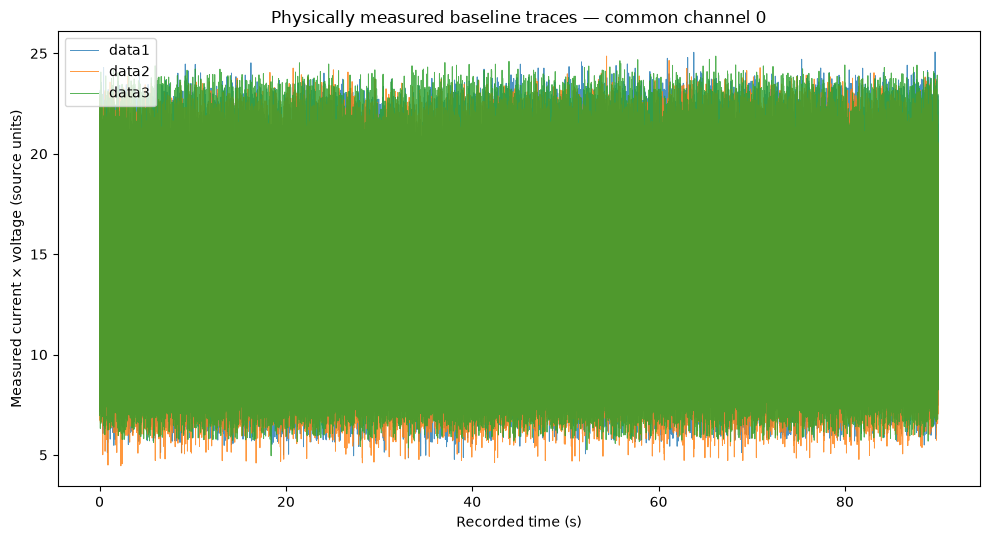

In [24]:
def load_lynsyn(path):
    path = Path(path)
    lines = path.read_text(encoding="utf-8", errors="replace").splitlines()
    header_idx = None
    for i, line in enumerate(lines):
        try:
            parts = next(csv.reader([line], delimiter=";"))
        except Exception:
            continue
        if parts and normalise_colname(parts[0]) == "time":
            header_idx = i
            break
    if header_idx is None:
        raise ValueError(f"{path}: could not locate a header row beginning with Time")

    df = pd.read_csv(path, sep=";", skiprows=header_idx, header=0)
    raw_headers = [str(c).strip() for c in df.columns]
    df.columns = [normalise_colname(c) for c in raw_headers]
    df.attrs["raw_headers"] = raw_headers
    df.attrs["header_line_1_based"] = header_idx + 1
    return df

def discover_current_voltage_pairs(df):
    currents, voltages = {}, {}
    for c in df.columns:
        m = re.fullmatch(r"current_(\d+)", c)
        if m:
            currents[int(m.group(1))] = c
        m = re.fullmatch(r"voltage_(\d+)", c)
        if m:
            voltages[int(m.group(1))] = c
    return [
        (idx, currents[idx], voltages[idx])
        for idx in sorted(set(currents) & set(voltages))
    ]

raw_frames = {}
sampling_rows = []
for dataset, path in RAW_TRACE_BY_DATASET.items():
    if path is None:
        continue
    df = load_lynsyn(path)
    raw_frames[dataset] = df
    if "time" not in df.columns:
        continue
    t = numeric(df["time"]).dropna().to_numpy()
    dt = np.diff(t)
    dt = dt[np.isfinite(dt) & (dt > 0)]
    sampling_rows.append({
        "dataset": dataset,
        "file": path.name,
        "n_samples": len(df),
        "duration_s": float(t[-1] - t[0]) if len(t) >= 2 else np.nan,
        "median_dt_s": float(np.median(dt)) if len(dt) else np.nan,
        "average_sampling_hz_from_duration":
            float((len(t)-1)/(t[-1]-t[0]))
            if len(t) >= 2 and t[-1] > t[0] else np.nan,
        "header_line_1_based": df.attrs.get("header_line_1_based"),
    })

raw_sampling = pd.DataFrame(sampling_rows)
raw_sampling.to_csv(TABLE_ROOT / "raw_sampling_evidence.csv", index=False)
display(raw_sampling)

# Raw Lynsyn traces are the physically measured baseline evidence.
# The current x voltage product is kept in source units because the export
# headers do not establish engineering-unit scaling.
baseline_rows = []
for dataset, df in raw_frames.items():
    if "time" not in df.columns:
        continue
    for idx, current_col, voltage_col in discover_current_voltage_pairs(df):
        y = numeric(df[current_col]) * numeric(df[voltage_col])
        baseline_rows.append({
            "dataset": dataset,
            "channel_index": idx,
            "n": int(y.notna().sum()),
            "mean_current_x_voltage": float(y.mean()),
            "std_current_x_voltage": float(y.std(ddof=1)),
            "median_current_x_voltage": float(y.median()),
        })

raw_baseline_summary = pd.DataFrame(baseline_rows)
raw_baseline_summary.to_csv(TABLE_ROOT / "physically_measured_baseline_trace_summary.csv", index=False)
display(raw_baseline_summary)

# One common-channel overview using the same axes for every trace.
common_channels = None
for df in raw_frames.values():
    ids = {idx for idx, _, _ in discover_current_voltage_pairs(df)}
    common_channels = ids if common_channels is None else common_channels & ids
common_channels = sorted(common_channels or [])

if common_channels:
    idx = common_channels[0]
    plt.figure(figsize=(10, 5.5))
    for dataset, df in raw_frames.items():
        pair_map = {i: (c, v) for i, c, v in discover_current_voltage_pairs(df)}
        c, v = pair_map[idx]
        t = numeric(df["time"])
        y = numeric(df[c]) * numeric(df[v])
        plt.plot(t, y, linewidth=0.7, alpha=0.8, label=dataset)
    plt.xlabel("Recorded time (s)")
    plt.ylabel("Measured current × voltage (source units)")
    plt.title(f"Physically measured baseline traces — common channel {idx}")
    plt.legend()
    plt.tight_layout()
    plt.savefig(FIGURE_ROOT / "baseline_trace_common_scale.png", dpi=300)
    plt.show()

## 5. Final frozen-dataset result summaries

In [25]:
def summarise_power_file(path):
    df = read_project_csv(path)
    required = {"source_power_data", "observation_new"}
    if not required.issubset(df.columns):
        return None

    source = numeric(df["source_power_data"])
    controlled = numeric(df["observation_new"])
    valid = source.notna() & controlled.notna()
    source = source[valid]
    controlled = controlled[valid]

    source_sum = float(source.sum()) if len(source) else np.nan
    controlled_sum = float(controlled.sum()) if len(controlled) else np.nan
    reduction = (
        100.0 * (source_sum - controlled_sum) / source_sum
        if np.isfinite(source_sum) and not np.isclose(source_sum, 0)
        else np.nan
    )

    row = {
        "n_paired_records": int(len(source)),
        "stored_source_mean": float(source.mean()) if len(source) else np.nan,
        "simulator_controlled_mean": float(controlled.mean()) if len(controlled) else np.nan,
        "paired_sample_reduction_pct": reduction,
        "recorded_efficiency_mean_pct":
            100.0 * float(numeric(df["efficiency"]).mean())
            if "efficiency" in df.columns else np.nan,
        "reward_mean":
            float(numeric(df["reward"]).mean())
            if "reward" in df.columns else np.nan,
        "has_embedded_header": bool(df.attrs.get("has_header")),
        "schema_source": df.attrs.get("schema_source"),
    }
    return row

def collect_verified_result_summaries(datasets):
    rows = []
    for dataset in datasets:
        for seed in EXPECTED_SEEDS:
            for algorithm in EXPECTED_ALGORITHMS:
                audit_row = evaluation_trace_audit[
                    (evaluation_trace_audit["dataset"] == dataset)
                    & (evaluation_trace_audit["seed"] == seed)
                    & (evaluation_trace_audit["algorithm"] == algorithm)
                ]
                if audit_row.empty or not bool(
                    audit_row["eligible_for_evaluation_analysis"].iloc[0]
                ):
                    continue
                path = DATASET_ROOTS[dataset] / str(seed) / f"{algorithm}_power.csv"
                summary = summarise_power_file(path)
                if summary is None:
                    continue
                rows.append({
                    "dataset": dataset,
                    "seed": seed,
                    "algorithm": algorithm,
                    "file": str(path.relative_to(ROOT)),
                    **summary,
                })
    return pd.DataFrame(rows)

In [26]:
if FROZEN_DATASET_READY:
    frozen_results = collect_verified_result_summaries(expected_datasets)
else:
    frozen_results = pd.DataFrame()

frozen_results.to_csv(
    TABLE_ROOT / "frozen_dataset_file_summaries.csv", index=False
)
display(frozen_results.head(20))

if FROZEN_DATASET_READY and not frozen_results.empty:
    metric_cols = [
        "recorded_efficiency_mean_pct",
        "paired_sample_reduction_pct",
        "reward_mean",
        "stored_source_mean",
        "simulator_controlled_mean",
    ]
    metric_cols = [c for c in metric_cols if c in frozen_results.columns]

    seed_metrics = (
        frozen_results
        .groupby(["seed", "algorithm"], as_index=False)[metric_cols]
        .mean(numeric_only=True)
    )
else:
    metric_cols = []
    seed_metrics = pd.DataFrame()

seed_metrics.to_csv(TABLE_ROOT / "final_seed_level_metrics.csv", index=False)
display(seed_metrics)

summary_rows = []
if FROZEN_DATASET_READY:
    for algorithm, g in seed_metrics.groupby("algorithm"):
        for metric in metric_cols:
            values = g[metric].dropna()
            lo, hi = t_ci(values)
            summary_rows.append({
                "algorithm": algorithm,
                "metric": metric,
                "n_independent_seeds": len(values),
                "mean": float(values.mean()) if len(values) else np.nan,
                "std": float(values.std(ddof=1)) if len(values) > 1 else np.nan,
                "median": float(values.median()) if len(values) else np.nan,
                "min": float(values.min()) if len(values) else np.nan,
                "max": float(values.max()) if len(values) else np.nan,
                "ci95_low": lo,
                "ci95_high": hi,
            })

final_seed_summary = pd.DataFrame(summary_rows)
final_seed_summary.to_csv(
    TABLE_ROOT / "final_seed_summary_mean_sd_ci.csv", index=False
)
display(final_seed_summary)

""


""


""


## 6. Final exact paired comparisons and Holm correction

In [27]:
paired_rows = []
if FROZEN_DATASET_READY:
    for metric in [
        c for c in
        ["recorded_efficiency_mean_pct", "paired_sample_reduction_pct"]
        if c in seed_metrics.columns
    ]:
        wide = seed_metrics.pivot(
            index="seed", columns="algorithm", values=metric
        )
        for a, b in combinations(wide.columns, 2):
            pair = wide[[a, b]].dropna()
            diff = pair[a] - pair[b]
            sd = diff.std(ddof=1)
            paired_rows.append({
                "metric": metric,
                "algorithm_a": a,
                "algorithm_b": b,
                "n_paired_seeds": len(pair),
                "mean_difference_a_minus_b": float(diff.mean())
                    if len(diff) else np.nan,
                "paired_effect_size_dz":
                    float(diff.mean()/sd)
                    if len(diff) > 1 and np.isfinite(sd) and sd > 0
                    else np.nan,
                "exact_two_sided_signflip_p":
                    exact_signflip_pvalue(diff)
                    if len(diff) >= 2 else np.nan,
            })

final_paired = pd.DataFrame(paired_rows)
if not final_paired.empty:
    final_paired["holm_adjusted_p"] = np.nan
    for metric, idx in final_paired.groupby("metric").groups.items():
        final_paired.loc[idx, "holm_adjusted_p"] = holm_adjust(
            final_paired.loc[idx, "exact_two_sided_signflip_p"]
        )

final_paired.to_csv(TABLE_ROOT / "final_paired_seed_comparisons.csv",
                    index=False)
display(final_paired)

if FROZEN_DATASET_READY and len(EXPECTED_SEEDS) == 5:
    print(
        "Five-seed exact-test note: the smallest possible non-zero two-sided "
        "sign-flip p-value is 2/2^5 = 0.0625."
    )

""


## 7. Final seed-point figures

In [28]:
if FROZEN_DATASET_READY and not seed_metrics.empty:
    for metric, ylabel, filename in [
        ("paired_sample_reduction_pct",
         "Source-to-simulator-controlled reduction (%)",
         "final_reduction_seed_points.png"),
        ("recorded_efficiency_mean_pct",
         "Recorded efficiency (%)",
         "final_recorded_efficiency_seed_points.png"),
    ]:
        if metric not in seed_metrics.columns:
            continue
        plt.figure(figsize=(9, 5.5))
        for algorithm, g in seed_metrics.groupby("algorithm"):
            plt.scatter(
                np.full(len(g), algorithm.upper(), dtype=object),
                g[metric], s=55, alpha=0.8
            )
        plt.ylabel(ylabel)
        plt.xlabel("Algorithm")
        plt.title("Independent-seed results after frozen-dataset integration")
        plt.tight_layout()
        plt.savefig(FIGURE_ROOT / filename, dpi=300)
        plt.show()

## 8. Cross-dataset/trace robustness

`data1`, `data2` and `data3` are treated as three supplied evaluation datasets/traces. They are **not** relabelled as different image resolutions, CNN architectures or heterogeneous CPU workloads unless separate provenance proves those interventions.

In [29]:
cross_dataset_summary = pd.DataFrame()
rank_stability = pd.DataFrame()
leave_one_dataset_out = pd.DataFrame()

if FROZEN_DATASET_READY and not frozen_results.empty:
    dataset_seed = (
        frozen_results
        .groupby(["dataset", "seed", "algorithm"], as_index=False)[
            ["paired_sample_reduction_pct", "recorded_efficiency_mean_pct"]
        ]
        .mean()
    )

    summary_rows = []
    for metric in ["paired_sample_reduction_pct",
                   "recorded_efficiency_mean_pct"]:
        if metric not in dataset_seed.columns:
            continue
        for algorithm, g in dataset_seed.groupby("algorithm"):
            dataset_means = g.groupby("dataset")[metric].mean()
            overall = dataset_means.mean()
            sd = dataset_means.std(ddof=1)
            cv = 100.0 * sd / abs(overall) if len(dataset_means) > 1 and overall != 0 else np.nan
            summary_rows.append({
                "algorithm": algorithm,
                "metric": metric,
                "n_supplied_datasets": dataset_means.size,
                "mean_across_dataset_means": overall,
                "between_dataset_std": sd,
                "between_dataset_cv_pct": cv,
                "between_dataset_range":
                    dataset_means.max() - dataset_means.min(),
                "dataset_seed_fraction_positive":
                    float((g[metric] > 0).mean())
                    if metric == "paired_sample_reduction_pct" else np.nan,
            })
    cross_dataset_summary = pd.DataFrame(summary_rows)

    # Ranking stability by dataset.
    rank_rows = []
    for dataset, g in dataset_seed.groupby("dataset"):
        for metric in ["paired_sample_reduction_pct",
                       "recorded_efficiency_mean_pct"]:
            if metric not in g.columns:
                continue
            means = g.groupby("algorithm")[metric].mean().sort_values(
                ascending=False
            )
            for rank, (algorithm, value) in enumerate(means.items(), 1):
                rank_rows.append({
                    "dataset": dataset,
                    "metric": metric,
                    "algorithm": algorithm,
                    "rank": rank,
                    "mean_value": value,
                })
    rank_stability = pd.DataFrame(rank_rows)

    # Leave-one-dataset-out seed-level mean.
    loo_rows = []
    datasets = sorted(dataset_seed["dataset"].unique())
    for omitted in datasets:
        kept = dataset_seed[dataset_seed["dataset"] != omitted]
        seed_agg = kept.groupby(
            ["seed", "algorithm"], as_index=False
        )["paired_sample_reduction_pct"].mean()
        for algorithm, g in seed_agg.groupby("algorithm"):
            vals = g["paired_sample_reduction_pct"].dropna()
            lo, hi = t_ci(vals)
            loo_rows.append({
                "omitted_dataset": omitted,
                "algorithm": algorithm,
                "n_seeds": len(vals),
                "mean_reduction_pct": vals.mean(),
                "ci95_low": lo,
                "ci95_high": hi,
            })
    leave_one_dataset_out = pd.DataFrame(loo_rows)

cross_dataset_summary.to_csv(
    TABLE_ROOT / "cross_dataset_algorithm_summary.csv", index=False
)
rank_stability.to_csv(
    TABLE_ROOT / "cross_dataset_rank_stability.csv", index=False
)
leave_one_dataset_out.to_csv(
    TABLE_ROOT / "leave_one_dataset_out_summary.csv", index=False
)

display(cross_dataset_summary)
display(rank_stability)
display(leave_one_dataset_out)

""


""


""


## 9. Conditional controller-overhead break-even budget

In [30]:
break_even_rows = []
if FROZEN_DATASET_READY and "paired_sample_reduction_pct" in seed_metrics.columns:
    for algorithm, g in seed_metrics.groupby("algorithm"):
        values = g["paired_sample_reduction_pct"].dropna()
        lo, hi = t_ci(values)
        break_even_rows.append({
            "algorithm": algorithm,
            "n_seeds": len(values),
            "mean_break_even_overhead_pct_of_source": values.mean(),
            "minimum_observed_seed_break_even_pct": values.min(),
            "maximum_observed_seed_break_even_pct": values.max(),
            "ci95_low": lo,
            "ci95_high": hi,
            "actual_controller_overhead_measured": False,
        })

break_even = pd.DataFrame(break_even_rows)
break_even.to_csv(
    TABLE_ROOT / "controller_overhead_break_even_budget.csv", index=False
)
display(break_even)

scenario_rows = []
for _, row in break_even.iterrows():
    for assumed_overhead in [0, 2, 5, 10, 20, 30]:
        scenario_rows.append({
            "algorithm": row["algorithm"],
            "assumed_controller_overhead_pct_of_source": assumed_overhead,
            "conditional_net_reduction_pct":
                row["mean_break_even_overhead_pct_of_source"]
                - assumed_overhead,
        })
overhead_sensitivity = pd.DataFrame(scenario_rows)
overhead_sensitivity.to_csv(
    TABLE_ROOT / "controller_overhead_hypothetical_sensitivity.csv",
    index=False
)
display(overhead_sensitivity)

""


""


## 10. Energy–source-defined-constraint trade-off

The `*_efficiency.csv` exports contain `flag_min_efficiency_true_count` and `all_flag_count`. These are used exactly as labelled to derive a source-defined flag rate.

The flag is **not** renamed latency violation, deadline miss or FPS failure.

In [31]:
constraint_rows = []
if FROZEN_DATASET_READY:
    for dataset in expected_datasets:
        droot = DATASET_ROOTS[dataset]
        for seed in EXPECTED_SEEDS:
            for algorithm in EXPECTED_ALGORITHMS:
                path = droot / str(seed) / f"{algorithm}_efficiency.csv"
                if not path.exists():
                    continue
                df = read_project_csv(path)
                required = {
                    "flag_min_efficiency_true_count", "all_flag_count"
                }
                if not required.issubset(df.columns):
                    continue
                true_count = numeric(
                    df["flag_min_efficiency_true_count"]
                ).sum(min_count=1)
                all_count = numeric(df["all_flag_count"]).sum(min_count=1)
                violation = (
                    100.0 * true_count / all_count
                    if np.isfinite(all_count) and all_count > 0
                    else np.nan
                )
                constraint_rows.append({
                    "dataset": dataset,
                    "seed": seed,
                    "algorithm": algorithm,
                    "source_defined_violation_pct": violation,
                })

constraint_file = pd.DataFrame(constraint_rows)

if FROZEN_DATASET_READY and not constraint_file.empty:
    constraint_seed = (
        constraint_file
        .groupby(["seed", "algorithm"], as_index=False)[
            "source_defined_violation_pct"
        ]
        .mean()
    )
    pareto_seed = seed_metrics[
        ["seed", "algorithm", "paired_sample_reduction_pct"]
    ].merge(
        constraint_seed, on=["seed", "algorithm"], how="inner"
    )
else:
    constraint_seed = pd.DataFrame()
    pareto_seed = pd.DataFrame()

def pareto_nondominated(df, benefit_col, cost_col):
    result = []
    vals = df[[benefit_col, cost_col]].to_numpy(dtype=float)
    for i, (benefit_i, cost_i) in enumerate(vals):
        dominated = False
        for j, (benefit_j, cost_j) in enumerate(vals):
            if i == j:
                continue
            if (
                benefit_j >= benefit_i and cost_j <= cost_i
                and (benefit_j > benefit_i or cost_j < cost_i)
            ):
                dominated = True
                break
        result.append(not dominated)
    return np.asarray(result, dtype=bool)

memberships = []
if not pareto_seed.empty:
    for seed, g in pareto_seed.groupby("seed"):
        gg = g.dropna(
            subset=["paired_sample_reduction_pct",
                    "source_defined_violation_pct"]
        ).copy()
        if gg.empty:
            continue
        gg["pareto_nondominated"] = pareto_nondominated(
            gg, "paired_sample_reduction_pct",
            "source_defined_violation_pct"
        )
        memberships.append(gg)
pareto_seed = (
    pd.concat(memberships, ignore_index=True)
    if memberships else pd.DataFrame()
)

if not pareto_seed.empty:
    pareto_algorithm = (
        pareto_seed.groupby("algorithm", as_index=False)
        .agg(
            n_seeds=("seed", "nunique"),
            pareto_frontier_frequency=("pareto_nondominated", "mean"),
            mean_reduction_pct=("paired_sample_reduction_pct", "mean"),
            mean_source_defined_violation_pct=(
                "source_defined_violation_pct", "mean"
            ),
        )
    )
    pareto_algorithm["mean_level_pareto_nondominated"] = pareto_nondominated(
        pareto_algorithm, "mean_reduction_pct",
        "mean_source_defined_violation_pct"
    )
else:
    pareto_algorithm = pd.DataFrame()

constraint_pairwise_rows = []
if not constraint_seed.empty:
    wide = constraint_seed.pivot(
        index="seed", columns="algorithm",
        values="source_defined_violation_pct"
    )
    for a, b in combinations(wide.columns, 2):
        pair = wide[[a, b]].dropna()
        diff = pair[a] - pair[b]
        sd = diff.std(ddof=1)
        constraint_pairwise_rows.append({
            "algorithm_a": a,
            "algorithm_b": b,
            "n_paired_seeds": len(pair),
            "mean_violation_difference_a_minus_b_pp":
                diff.mean() if len(diff) else np.nan,
            "paired_effect_size_dz":
                diff.mean()/sd
                if len(diff) > 1 and np.isfinite(sd) and sd > 0
                else np.nan,
            "exact_two_sided_signflip_p":
                exact_signflip_pvalue(diff)
                if len(diff) >= 2 else np.nan,
        })
constraint_pairwise = pd.DataFrame(constraint_pairwise_rows)
if not constraint_pairwise.empty:
    constraint_pairwise["holm_adjusted_p"] = holm_adjust(
        constraint_pairwise["exact_two_sided_signflip_p"]
    )

pareto_seed.to_csv(
    TABLE_ROOT / "energy_constraint_pareto_seed_points.csv", index=False
)
pareto_algorithm.to_csv(
    TABLE_ROOT / "energy_constraint_pareto_algorithm_summary.csv",
    index=False
)
constraint_pairwise.to_csv(
    TABLE_ROOT / "source_defined_constraint_pairwise_tests.csv",
    index=False
)

display(pareto_algorithm)
display(constraint_pairwise)

if not pareto_seed.empty:
    plt.figure(figsize=(8, 5.8))
    for algorithm, g in pareto_seed.groupby("algorithm"):
        plt.scatter(
            g["source_defined_violation_pct"],
            g["paired_sample_reduction_pct"],
            s=50, alpha=0.75, label=algorithm.upper()
        )
    plt.xlabel("Source-defined flag rate (%)")
    plt.ylabel("Source-to-simulator-controlled reduction (%)")
    plt.title("Observed reduction–constraint trade-off")
    plt.legend()
    plt.tight_layout()
    plt.savefig(FIGURE_ROOT / "energy_constraint_pareto.png", dpi=300)
    plt.show()

""


""


## 11. Action-component observational sensitivity

Action dimensions remain anonymous (`action_0`, `action_1`, …). They are not renamed CPU/GPU without implementation evidence.

The analysis is observational and must not be described as a CPU-only/GPU-only/joint causal ablation.

In [32]:
def parse_action(value):
    if pd.isna(value):
        return []
    if isinstance(value, (int, float, np.number)):
        return [float(value)]
    text = str(value)
    vals = re.findall(
        r"[-+]?(?:\d*\.\d+|\d+\.?)(?:[eE][-+]?\d+)?", text
    )
    return [float(v) for v in vals]

def safe_spearman(x, y):
    pair = pd.DataFrame({"x": x, "y": y}).dropna()
    if len(pair) < 3 or pair["x"].std() == 0 or pair["y"].std() == 0:
        return np.nan
    return float(stats.spearmanr(pair["x"], pair["y"]).statistic)

action_rows = []
MAX_ACTION_ROWS_PER_FILE = 5000

if FROZEN_DATASET_READY:
    for dataset in expected_datasets:
        for seed in EXPECTED_SEEDS:
            for algorithm in EXPECTED_ALGORITHMS:
                path = DATASET_ROOTS[dataset] / str(seed) / f"{algorithm}_power.csv"
                df = read_project_csv(path)
                if "action" not in df.columns:
                    continue
                if len(df) > MAX_ACTION_ROWS_PER_FILE:
                    idx = np.linspace(
                        0, len(df)-1, MAX_ACTION_ROWS_PER_FILE, dtype=int
                    )
                    df = df.iloc[idx].copy()

                parsed = df["action"].map(parse_action)
                max_dim = max((len(x) for x in parsed), default=0)

                targets = [
                    c for c in
                    ["observation_new", "source_power_data", "efficiency",
                     "reward", "cpu_count", "gpu_count"]
                    if c in df.columns
                ]

                for dim in range(max_dim):
                    action_values = pd.Series(
                        [
                            values[dim] if len(values) > dim else np.nan
                            for values in parsed
                        ],
                        index=df.index,
                        dtype="float64",
                    )
                    for target in targets:
                        action_rows.append({
                            "dataset": dataset,
                            "seed": seed,
                            "algorithm": algorithm,
                            "action_component": f"action_{dim}",
                            "target": target,
                            "n_sampled_records":
                                int((action_values.notna()
                                     & numeric(df[target]).notna()).sum()),
                            "spearman_rho":
                                safe_spearman(
                                    action_values, numeric(df[target])
                                ),
                        })

action_sensitivity = pd.DataFrame(action_rows)
action_sensitivity.to_csv(
    TABLE_ROOT / "action_component_file_level_sensitivity.csv",
    index=False
)

if not action_sensitivity.empty:
    action_seed = (
        action_sensitivity
        .groupby(
            ["seed", "algorithm", "action_component", "target"],
            as_index=False
        )["spearman_rho"]
        .mean()
    )
    action_summary_rows = []
    for keys, g in action_seed.groupby(
        ["algorithm", "action_component", "target"]
    ):
        vals = g["spearman_rho"].dropna()
        lo, hi = t_ci(vals)
        action_summary_rows.append({
            "algorithm": keys[0],
            "action_component": keys[1],
            "target": keys[2],
            "n_seeds": len(vals),
            "mean_spearman_rho": vals.mean() if len(vals) else np.nan,
            "ci95_low": lo,
            "ci95_high": hi,
        })
    action_summary = pd.DataFrame(action_summary_rows)
else:
    action_seed = pd.DataFrame()
    action_summary = pd.DataFrame()

action_summary.to_csv(
    TABLE_ROOT / "action_component_across_seed_sensitivity.csv",
    index=False
)
display(action_summary)

""


## 12. State/history predictive sensitivity

This is a post-hoc predictive diagnostic. It tests whether short history and the source-defined CPU/GPU count fields add predictive information for the next simulator-controlled observation.

It does **not** show that retraining the RL policy with those variables would improve control performance.

In [33]:
state_history_rows = []

try:
    from sklearn.linear_model import Ridge
    from sklearn.preprocessing import StandardScaler
    from sklearn.pipeline import make_pipeline
    SKLEARN_AVAILABLE = True
except Exception as exc:
    SKLEARN_AVAILABLE = False
    print("scikit-learn unavailable; state/history analysis skipped:", exc)

def action_matrix(series, max_dim=2):
    parsed = series.map(parse_action)
    data = {}
    for dim in range(max_dim):
        data[f"action_{dim}"] = [
            values[dim] if len(values) > dim else np.nan
            for values in parsed
        ]
    return pd.DataFrame(data, index=series.index)

def time_ordered_r2(X, y, train_fraction=0.7):
    frame = X.copy()
    frame["__y__"] = y
    frame = frame.replace([np.inf, -np.inf], np.nan).dropna()
    if len(frame) < 50:
        return np.nan, len(frame)
    cut = int(len(frame) * train_fraction)
    if cut < 20 or len(frame) - cut < 10:
        return np.nan, len(frame)
    Xtr = frame.iloc[:cut].drop(columns="__y__")
    ytr = frame.iloc[:cut]["__y__"]
    Xte = frame.iloc[cut:].drop(columns="__y__")
    yte = frame.iloc[cut:]["__y__"]
    model = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
    model.fit(Xtr, ytr)
    return float(model.score(Xte, yte)), len(frame)

MAX_STATE_ROWS_PER_FILE = 10000

if FROZEN_DATASET_READY and SKLEARN_AVAILABLE:
    for dataset in expected_datasets:
        for seed in EXPECTED_SEEDS:
            for algorithm in EXPECTED_ALGORITHMS:
                path = DATASET_ROOTS[dataset] / str(seed) / f"{algorithm}_power.csv"
                df = read_project_csv(path)
                if "observation_new" not in df.columns:
                    continue
                if len(df) > MAX_STATE_ROWS_PER_FILE:
                    idx = np.linspace(
                        0, len(df)-1, MAX_STATE_ROWS_PER_FILE, dtype=int
                    )
                    df = df.iloc[idx].copy()

                obs = numeric(df["observation_new"]).reset_index(drop=True)
                acts = (
                    action_matrix(df["action"].reset_index(drop=True), 2)
                    if "action" in df.columns
                    else pd.DataFrame(index=range(len(df)))
                )

                base = pd.DataFrame({"obs_t": obs})
                base = pd.concat([base, acts.reset_index(drop=True)], axis=1)
                target = obs.shift(-1)

                representations = {"current_observation_and_action": base}

                counts = [
                    c for c in ["cpu_count", "gpu_count"] if c in df.columns
                ]
                if counts:
                    with_counts = base.copy()
                    for c in counts:
                        with_counts[c] = numeric(
                            df[c].reset_index(drop=True)
                        )
                    representations["plus_source_defined_counts"] = with_counts
                else:
                    with_counts = base.copy()

                history = with_counts.copy()
                for c in list(with_counts.columns):
                    history[f"{c}_lag1"] = with_counts[c].shift(1)
                    history[f"{c}_lag2"] = with_counts[c].shift(2)
                representations["plus_two_step_history"] = history

                for name, X in representations.items():
                    r2, n = time_ordered_r2(X, target)
                    state_history_rows.append({
                        "dataset": dataset,
                        "seed": seed,
                        "algorithm": algorithm,
                        "representation": name,
                        "time_ordered_test_r2": r2,
                        "n_usable_records": n,
                    })

state_history = pd.DataFrame(state_history_rows)
state_history.to_csv(
    TABLE_ROOT / "state_history_file_level_sensitivity.csv", index=False
)

if not state_history.empty:
    state_seed = (
        state_history
        .groupby(["seed", "algorithm", "representation"], as_index=False)[
            "time_ordered_test_r2"
        ]
        .mean()
    )
    summary_rows = []
    for keys, g in state_seed.groupby(["algorithm", "representation"]):
        vals = g["time_ordered_test_r2"].dropna()
        lo, hi = t_ci(vals)
        summary_rows.append({
            "algorithm": keys[0],
            "representation": keys[1],
            "n_seeds": len(vals),
            "mean_time_ordered_test_r2": vals.mean()
                if len(vals) else np.nan,
            "ci95_low": lo,
            "ci95_high": hi,
        })
    state_history_summary = pd.DataFrame(summary_rows)
else:
    state_history_summary = pd.DataFrame()

state_history_summary.to_csv(
    TABLE_ROOT / "state_history_across_seed_sensitivity.csv",
    index=False
)
display(state_history_summary)

""


## 13. Record-density robustness

Thinning the stored sequence tests whether the derived source-to-controlled reduction is sensitive to record density. It is **not** a controller-update-period experiment.

In [34]:
THINNING_STRIDES = [1, 2, 5, 10, 20]
thinning_rows = []

if FROZEN_DATASET_READY:
    for dataset in expected_datasets:
        for seed in EXPECTED_SEEDS:
            for algorithm in EXPECTED_ALGORITHMS:
                path = DATASET_ROOTS[dataset] / str(seed) / f"{algorithm}_power.csv"
                df = read_project_csv(path)
                if not {"source_power_data", "observation_new"}.issubset(df.columns):
                    continue
                src = numeric(df["source_power_data"])
                ctl = numeric(df["observation_new"])
                valid = src.notna() & ctl.notna()
                src = src[valid].reset_index(drop=True)
                ctl = ctl[valid].reset_index(drop=True)
                for stride in THINNING_STRIDES:
                    s = src.iloc[::stride]
                    c = ctl.iloc[::stride]
                    ssum = s.sum()
                    reduction = (
                        100.0 * (ssum - c.sum()) / ssum
                        if np.isfinite(ssum) and not np.isclose(ssum, 0)
                        else np.nan
                    )
                    thinning_rows.append({
                        "dataset": dataset,
                        "seed": seed,
                        "algorithm": algorithm,
                        "stride": stride,
                        "n_records": len(s),
                        "paired_sample_reduction_pct": reduction,
                    })

thinning = pd.DataFrame(thinning_rows)
thinning.to_csv(
    TABLE_ROOT / "record_thinning_file_level.csv", index=False
)

if not thinning.empty:
    thinning_seed = (
        thinning
        .groupby(["seed", "algorithm", "stride"], as_index=False)[
            "paired_sample_reduction_pct"
        ]
        .mean()
    )
    base = thinning_seed[thinning_seed["stride"] == 1][
        ["seed", "algorithm", "paired_sample_reduction_pct"]
    ].rename(columns={"paired_sample_reduction_pct": "stride1_reduction_pct"})
    thinning_seed = thinning_seed.merge(
        base, on=["seed", "algorithm"], how="left"
    )
    thinning_seed["difference_from_stride1_pp"] = (
        thinning_seed["paired_sample_reduction_pct"]
        - thinning_seed["stride1_reduction_pct"]
    )
    thinning_summary = (
        thinning_seed.groupby(["algorithm", "stride"], as_index=False)
        .agg(
            mean_reduction_pct=("paired_sample_reduction_pct", "mean"),
            mean_difference_from_stride1_pp=(
                "difference_from_stride1_pp", "mean"
            ),
            max_abs_difference_from_stride1_pp=(
                "difference_from_stride1_pp",
                lambda x: np.nanmax(np.abs(x))
            ),
        )
    )
else:
    thinning_seed = pd.DataFrame()
    thinning_summary = pd.DataFrame()

thinning_summary.to_csv(
    TABLE_ROOT / "record_thinning_sensitivity_summary.csv",
    index=False
)
display(thinning_summary)

""


## 14. Temporal stability over the available physical baseline window

The raw trace can be examined for temporal drift. No temperature measurements are present, so this analysis cannot establish or exclude thermal throttling.

In [35]:
def cusum_change_candidate(values, max_points=25000):
    x = pd.Series(values, dtype="float64").dropna().to_numpy()
    if len(x) < 20:
        return np.nan, np.nan, np.nan
    if len(x) > max_points:
        idx = np.linspace(0, len(x)-1, max_points, dtype=int)
        x = x[idx]
    sd = np.std(x, ddof=1)
    if not np.isfinite(sd) or sd == 0:
        return np.nan, np.nan, np.nan
    centered = x - np.mean(x)
    cs = np.cumsum(centered)
    k = int(np.argmax(np.abs(cs)))
    frac = (k + 1) / len(x)
    if k < 5 or k > len(x)-6:
        shift = np.nan
    else:
        shift = (np.mean(x[k+1:]) - np.mean(x[:k+1])) / sd
    return (
        float(frac),
        float(cs[k] / (sd * np.sqrt(len(x)))),
        float(shift) if np.isfinite(shift) else np.nan,
    )

drift_rows = []
for dataset, df in raw_frames.items():
    if "time" not in df.columns:
        continue
    t = numeric(df["time"]).to_numpy(dtype=float)
    if np.isfinite(t).sum() < 20:
        continue
    tmin, tmax = np.nanmin(t), np.nanmax(t)
    duration = tmax - tmin
    if duration <= 0:
        continue
    rel_t = (t - tmin) / duration

    for idx, current_col, voltage_col in discover_current_voltage_pairs(df):
        y = (
            numeric(df[current_col]).to_numpy(dtype=float)
            * numeric(df[voltage_col]).to_numpy(dtype=float)
        )
        valid = np.isfinite(rel_t) & np.isfinite(y)
        rt, yy = rel_t[valid], y[valid]
        if len(yy) < 20:
            continue
        early = yy[rt < 1/3]
        middle = yy[(rt >= 1/3) & (rt < 2/3)]
        late = yy[rt >= 2/3]
        early_mean = float(np.mean(early)) if len(early) else np.nan
        late_mean = float(np.mean(late)) if len(late) else np.nan
        slope = stats.linregress(rt, yy).slope if np.std(rt) > 0 else np.nan
        rho = (
            stats.spearmanr(rt, yy).statistic
            if np.std(yy) > 0 else np.nan
        )
        cp_frac, cp_score, cp_shift_sd = cusum_change_candidate(yy)
        drift_rows.append({
            "dataset": dataset,
            "channel_index": idx,
            "duration_s": duration,
            "early_third_mean_current_x_voltage": early_mean,
            "middle_third_mean_current_x_voltage":
                float(np.mean(middle)) if len(middle) else np.nan,
            "late_third_mean_current_x_voltage": late_mean,
            "late_vs_early_pct_change":
                100.0 * (late_mean - early_mean) / abs(early_mean)
                if np.isfinite(early_mean) and not np.isclose(early_mean, 0)
                else np.nan,
            "linear_slope_per_normalised_recording": float(slope),
            "spearman_vs_normalised_time": float(rho),
            "cusum_candidate_position_fraction": cp_frac,
            "cusum_standardised_peak": cp_score,
            "candidate_post_vs_pre_shift_sd": cp_shift_sd,
            "thermal_interpretation_permitted": False,
        })

raw_temporal_drift = pd.DataFrame(drift_rows)
raw_temporal_drift.to_csv(
    TABLE_ROOT / "raw_trace_temporal_drift.csv", index=False
)
display(raw_temporal_drift)

,dataset,channel_index,duration_s,early_third_mean_current_x_voltage,middle_third_mean_current_x_voltage,late_third_mean_current_x_voltage,late_vs_early_pct_change,linear_slope_per_normalised_recording,spearman_vs_normalised_time,cusum_candidate_position_fraction,cusum_standardised_peak,candidate_post_vs_pre_shift_sd,thermal_interpretation_permitted
0,data1,0,89.9988,14.265551,14.373302,14.629235,2.549390,0.680817,0.045622,0.56452,-3.178454,0.081771,False
1,data1,1,89.9988,0.003941,0.003943,0.003946,0.112561,0.000006,0.052790,0.73892,-2.173083,0.071242,False
2,data1,2,89.9988,0.003156,0.003155,0.003180,0.746973,0.000035,0.076133,0.78648,-7.175897,0.270259,False
3,data1,3,89.9988,0.000000,0.000000,0.000000,NaN,0.000000,NaN,NaN,NaN,NaN,False
4,data1,4,89.9988,0.000000,0.000000,0.000000,NaN,0.000000,NaN,NaN,NaN,NaN,False
5,data1,5,89.9988,0.000000,0.000000,0.000000,NaN,0.000000,NaN,NaN,NaN,NaN,False
6,data1,6,89.9988,0.000000,0.000000,0.000000,NaN,0.000000,NaN,NaN,NaN,NaN,False
7,data2,0,89.9989,14.010524,14.156634,14.224918,1.530231,0.314575,0.021605,0.44168,-2.371366,0.060819,False
8,data2,1,89.9989,0.003941,0.003951,0.003951,0.248832,0.000012,0.110450,0.36756,-3.530898,0.096066,False
9,data2,2,89.9989,0.003139,0.003198,0.003195,1.786882,0.000066,0.138275,0.37676,-13.170324,0.354737,False


## 15. Availability audit for causal ablations and unsupported extensions

The current submission intentionally keeps the broader scope fixed. This audit prevents accidental claims that new reward ablations, CPU/GPU-only retraining, resolutions, CNN architectures or platforms were evaluated when their data are not present.

In [36]:
excluded_dirs = {
    ".git", ".venv", "venv", "site-packages", "__pycache__",
    "revision1_fixed_yolov4_analysis", "revision2_frozen_dataset_analysis",
    "current_data_recommendation_analysis",
}

variant_tokens = [
    "ppo_variant", "ppo_ablation", "energy_only", "latency_penalty",
    "cpu_only", "gpu_only", "joint_control", "416", "512", "608",
]

candidate_paths = []
for path in ROOT.rglob("*"):
    if not path.is_file():
        continue
    if any(part.lower() in excluded_dirs for part in path.parts):
        continue
    relative = str(path.relative_to(ROOT)).lower()
    if any(token in relative for token in variant_tokens):
        candidate_paths.append(str(path.relative_to(ROOT)))

availability_audit = pd.DataFrame([
    {
        "requested_extension": "energy-only versus constrained reward retraining",
        "current_dataset_evidence": "not established",
        "candidate_files_found": "; ".join(
            [p for p in candidate_paths
             if "energy_only" in p or "latency_penalty" in p]
        ),
        "manuscript_treatment": "limitation/future work unless provenance is supplied",
    },
    {
        "requested_extension": "CPU-only/GPU-only/joint-control causal ablation",
        "current_dataset_evidence": "not established",
        "candidate_files_found": "; ".join(
            [p for p in candidate_paths
             if any(x in p for x in ["cpu_only", "gpu_only", "joint_control"])]
        ),
        "manuscript_treatment": "limitation/future work",
    },
    {
        "requested_extension": "416/512/608 resolution validation",
        "current_dataset_evidence": "not established",
        "candidate_files_found": "; ".join(
            [p for p in candidate_paths
             if any(x in p for x in ["416", "512", "608"])]
        ),
        "manuscript_treatment": "remove/narrow claim; future work",
    },
    {
        "requested_extension": "second CNN architecture",
        "current_dataset_evidence": "not established",
        "candidate_files_found": "",
        "manuscript_treatment": "remove/narrow claim; future work",
    },
    {
        "requested_extension": "second physical hardware platform",
        "current_dataset_evidence": "not established",
        "candidate_files_found": "",
        "manuscript_treatment": "future work",
    },
])
availability_audit.to_csv(
    TABLE_ROOT / "unsupported_extension_availability_audit.csv",
    index=False
)
display(availability_audit)

,requested_extension,current_dataset_evidence,candidate_files_found,manuscript_treatment
0,energy-only versus constrained reward retraining,not established,,limitation/future work unless provenance is su...
1,CPU-only/GPU-only/joint-control causal ablation,not established,,limitation/future work
2,416/512/608 resolution validation,not established,,remove/narrow claim; future work
3,second CNN architecture,not established,,remove/narrow claim; future work
4,second physical hardware platform,not established,,future work


## 16. Final recommendation and manuscript-claim audit

In [37]:
coverage_rows = [
    (1, "Complete unfinished experiments/placeholders",
     "PARTIAL",
     "Frozen statistical tables can be completed; unsupported experiment placeholders must be removed."),
    (2, "Define actual control mechanism",
     "IMPLEMENTATION RECORDS REQUIRED",
     "Current result files do not establish physical actuator interface, mapping, limits or update period."),
    (3, "Make MDP/CMDP internally consistent",
     "PARTIAL",
     "Observed variables can be audited; transition timing/Lmax/enforcement require implementation evidence."),
    (4, "Correct PPO Algorithm 1/description",
     "EDITORIAL/SOURCE-CODE TASK",
     "No new experiment required."),
    (5, "Complete reproducibility information",
     "PARTIAL",
     "Seeds/data provenance are covered; hyperparameters/software/training budget still need records."),
    (6, "Multi-seed statistical analysis",
     "ADDRESSED WHEN FREEZE GATE PASSES",
     "Final mean/SD/CI, exact paired tests and effect sizes are generated."),
    (7, "Justify statistical design",
     "ADDRESSED WHEN FREEZE GATE PASSES",
     "data1/2/3 averaged within seed; seed is the inferential unit."),
    (8, "Workload generalisation",
     "NARROWED",
     "Only robustness across the three supplied datasets/traces is supported."),
    (9, "Controller overhead",
     "BOUND ONLY",
     "Break-even budget is conditional; actual controller energy is unmeasured."),
    (10, "Performance validation",
     "NOT MEASURED",
     "No measured latency/FPS/deadline data; source-defined flag is not relabelled."),
    (11, "Correct 34.6% claim",
     "ADDRESSED WHEN FREEZE GATE PASSES",
     "Replace with final frozen-dataset reduction statistics."),
    (12, "Rewrite >16% improvement",
     "ADDRESSED WHEN FREEZE GATE PASSES",
     "Use named comparator and exact percentage-point/relative definition."),
    (13, "Remove universality/optimality/portability claims",
     "EDITORIAL",
     "Restrict empirical claim to the tested fixed configuration."),
    (14, "Correct platform information",
     "IMPLEMENTATION RECORDS REQUIRED",
     "JetPack/CUDA/cuDNN/OS versions must come from deployment records."),
    (15, "Correct FLOPs/FLOP/s analysis",
     "EDITORIAL/ANALYTICAL",
     "No experiment required."),
    (16, "Rebuild related work",
     "LITERATURE TASK",
     "No experiment required."),
    (17, "Correct citations/bibliography",
     "EDITORIAL/LITERATURE TASK",
     "No experiment required."),
    (18, "Rewrite Abstract/Discussion/Conclusion",
     "AFTER RESULTS FREEZE",
     "Trace every numerical claim to final tables."),
    (19, "Author Contributions/Data Availability",
     "ADMINISTRATIVE",
     "Complete before submission."),
    (20, "Language proofread",
     "EDITORIAL",
     "Complete after scientific revision."),
    (21, "Explicit research questions",
     "EDITORIAL",
     "Align RQs with fixed-case energy reduction, algorithm comparison and trace robustness."),
    (22, "Reward and CPU/GPU causal ablations",
     "OBSERVATIONAL PROXIES ONLY",
     "Action/state/constraint diagnostics do not replace retraining ablations."),
    (23, "Deterministic baseline",
     "RECORDED SOURCE BASELINE ONLY",
     "Do not relabel the source trace as a Jetson DVFS/governor baseline."),
    (24, "Thermal/long-duration behaviour",
     "TEMPORAL DIAGNOSTIC ONLY",
     "No temperature measurement; no thermal-throttling claim."),
    (25, "Second physical platform",
     "FUTURE WORK",
     "No second platform in current data."),
    (26, "Closed-loop/deployment diagrams",
     "PARTIAL",
     "Data flow can be diagrammed; physical actuator timing remains unknown."),
    (27, "Release code/config/raw results",
     "PARTIAL",
     "Current notebooks/results can be released; missing implementation/config data cannot be reconstructed."),
]
recommendation_coverage = pd.DataFrame(
    coverage_rows,
    columns=[
        "recommendation_number", "recommendation",
        "status_after_frozen_dataset_analysis", "boundary"
    ],
)
recommendation_coverage.to_csv(
    TABLE_ROOT / "final_recommendation_coverage.csv", index=False
)
display(recommendation_coverage)

claim_rows = [
    ("Robust reduction across the three supplied datasets/traces",
     "SUPPORTED ONLY IF FREEZE GATE PASSES"),
    ("Generalisation across resolutions/CNN architectures/CPU workloads",
     "NOT EVIDENCED"),
    ("Actual controller overhead measured",
     "NOT EVIDENCED"),
    ("Conditional break-even overhead budget",
     "SUPPORTED ONLY IF FREEZE GATE PASSES"),
    ("Observed trade-off with source-defined constraint flag",
     "SUPPORTED ONLY IF FREEZE GATE PASSES"),
    ("Source-defined flag is latency/deadline violation",
     "NOT EVIDENCED"),
    ("Action-component observational sensitivity",
     "SUPPORTED ONLY IF FREEZE GATE PASSES"),
    ("CPU-only/GPU-only/joint causal ablation",
     "NOT EVIDENCED"),
    ("Temporal drift over available baseline recording",
     "SUPPORTED"),
    ("Absence of thermal throttling",
     "NOT EVIDENCED"),
    ("Cross-hardware portability",
     "NOT EVIDENCED"),
]
claim_audit = pd.DataFrame(claim_rows, columns=["claim", "status"])
claim_audit.to_csv(TABLE_ROOT / "final_manuscript_claim_audit.csv", index=False)
display(claim_audit)

,recommendation_number,recommendation,status_after_frozen_dataset_analysis,boundary
0,1,Complete unfinished experiments/placeholders,PARTIAL,Frozen statistical tables can be completed; un...
1,2,Define actual control mechanism,IMPLEMENTATION RECORDS REQUIRED,Current result files do not establish physical...
2,3,Make MDP/CMDP internally consistent,PARTIAL,Observed variables can be audited; transition ...
3,4,Correct PPO Algorithm 1/description,EDITORIAL/SOURCE-CODE TASK,No new experiment required.
4,5,Complete reproducibility information,PARTIAL,Seeds/data provenance are covered; hyperparame...
5,6,Multi-seed statistical analysis,ADDRESSED WHEN FREEZE GATE PASSES,"Final mean/SD/CI, exact paired tests and effec..."
6,7,Justify statistical design,ADDRESSED WHEN FREEZE GATE PASSES,data1/2/3 averaged within seed; seed is the in...
7,8,Workload generalisation,NARROWED,Only robustness across the three supplied data...
8,9,Controller overhead,BOUND ONLY,Break-even budget is conditional; actual contr...
9,10,Performance validation,NOT MEASURED,No measured latency/FPS/deadline data; source-...


,claim,status
0,Robust reduction across the three supplied dat...,SUPPORTED ONLY IF FREEZE GATE PASSES
1,Generalisation across resolutions/CNN architec...,NOT EVIDENCED
2,Actual controller overhead measured,NOT EVIDENCED
3,Conditional break-even overhead budget,SUPPORTED ONLY IF FREEZE GATE PASSES
4,Observed trade-off with source-defined constra...,SUPPORTED ONLY IF FREEZE GATE PASSES
5,Source-defined flag is latency/deadline violation,NOT EVIDENCED
6,Action-component observational sensitivity,SUPPORTED ONLY IF FREEZE GATE PASSES
7,CPU-only/GPU-only/joint causal ablation,NOT EVIDENCED
8,Temporal drift over available baseline recording,SUPPORTED
9,Absence of thermal throttling,NOT EVIDENCED


## 17. Final output index

In [38]:
print("Second-revision notebook complete.")
print("Freeze gate:", FROZEN_DATASET_READY)
print("Tables:", TABLE_ROOT)
print("Figures:", FIGURE_ROOT)

priority = [
    "frozen_dataset_readiness.csv",
    "final_seed_summary_mean_sd_ci.csv",
    "final_paired_seed_comparisons.csv",
    "cross_dataset_algorithm_summary.csv",
    "cross_dataset_rank_stability.csv",
    "leave_one_dataset_out_summary.csv",
    "controller_overhead_break_even_budget.csv",
    "energy_constraint_pareto_algorithm_summary.csv",
    "source_defined_constraint_pairwise_tests.csv",
    "action_component_across_seed_sensitivity.csv",
    "state_history_across_seed_sensitivity.csv",
    "record_thinning_sensitivity_summary.csv",
    "raw_trace_temporal_drift.csv",
    "final_recommendation_coverage.csv",
    "final_manuscript_claim_audit.csv",
]
print("\nPriority outputs:")
for name in priority:
    path = TABLE_ROOT / name
    print(" -", name, "OK" if path.exists() else "not generated / gated")

Second-revision notebook complete.
Freeze gate: False
Tables: /home/pedro/repo/Zheqi_Results/test/revision2_frozen_dataset_analysis/tables
Figures: /home/pedro/repo/Zheqi_Results/test/revision2_frozen_dataset_analysis/figures

Priority outputs:
 - frozen_dataset_readiness.csv OK
 - final_seed_summary_mean_sd_ci.csv OK
 - final_paired_seed_comparisons.csv OK
 - cross_dataset_algorithm_summary.csv OK
 - cross_dataset_rank_stability.csv OK
 - leave_one_dataset_out_summary.csv OK
 - controller_overhead_break_even_budget.csv OK
 - energy_constraint_pareto_algorithm_summary.csv OK
 - source_defined_constraint_pairwise_tests.csv OK
 - action_component_across_seed_sensitivity.csv OK
 - state_history_across_seed_sensitivity.csv OK
 - record_thinning_sensitivity_summary.csv OK
 - raw_trace_temporal_drift.csv OK
 - final_recommendation_coverage.csv OK
 - final_manuscript_claim_audit.csv OK
